In [1]:
'''Thoroughly document data preprocessing pipelines and transformation steps in a reproducible and 
automated manner, using tools like Jupyter Notebooks and data lineage tracking for governance compliance.'''

'Thoroughly document data preprocessing pipelines and transformation steps in a reproducible and \nautomated manner, using tools like Jupyter Notebooks and data lineage tracking for governance compliance.'

In [2]:
# import libraries for pipeline engineering and governance lineage tracking
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import json
import os
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [3]:
# load pharmacy sales dataset and inspect structural metadata
df = pd.read_csv('global_pharmacy_sales_data.csv')
print('dataset shape:', df.shape)
print('column list:', df.columns.tolist())
df.head()

dataset shape: (177990, 14)
column list: ['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# audit data quality missing values and integrity anomalies
print('missing values count per column:')
print(df.isnull().sum())
print('\nduplicate records count:', df.duplicated().sum())
print('\nstatistical summary of numerical attributes:')
df.describe()

missing values count per column:
date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64

duplicate records count: 2630

statistical summary of numerical attributes:


,year,month,day,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
count,177990.000000,177990.000000,177990.000000,177990.000000,177990.000000,177990.000000,177990.000000,177990.000000
mean,2022.499702,6.521754,15.730457,447.913849,52.554729,4552.991780,374.038109,0.333519
std,1.708113,3.448703,8.801170,338.924528,27.421909,346.608511,199.759193,0.471471
min,2020.000000,1.000000,1.000000,31.000000,5.000000,0.000000,30.000000,0.000000
25%,2021.000000,4.000000,8.000000,284.000000,28.770000,4443.000000,200.000000,0.000000
50%,2023.000000,7.000000,16.000000,387.000000,52.600000,4598.000000,374.000000,0.000000
75%,2024.000000,10.000000,23.000000,529.000000,76.310000,4735.000000,547.000000,1.000000
max,2025.000000,12.000000,31.000000,8704.000000,100.000000,5124.000000,720.000000,1.000000


In [5]:
# initialize governance compliant data lineage tracking registry
lineage_registry = []

def record_lineage(stage, step_name, input_features, output_features, transformation_logic, status="compliant"):
    entry = {
        'timestamp': datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'pipeline_stage': stage,
        'step_name': step_name,
        'input_features': input_features,
        'output_features': output_features,
        'transformation_logic': transformation_logic,
        'row_count': len(df),
        'governance_status': status
    }
    lineage_registry.append(entry)

record_lineage('ingestion', 'raw_dataset_ingestion', ['global_pharmacy_sales_data.csv'], list(df.columns), 'loaded raw csv source data')
print('lineage registry initialized with ingestion entry')

lineage registry initialized with ingestion entry


In [6]:
# execute cleaning and feature engineering transformations
df['revenue'] = df['units_sold'] * df['unit_price']
df['order_date'] = pd.to_datetime(df['date'])
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['order_quarter'] = df['order_date'].dt.quarter
df['order_dayofweek'] = df['order_date'].dt.dayofweek
df['is_weekend'] = (df['order_dayofweek'] >= 5).astype(int)
df['stock_to_sales_ratio'] = df['stock_level'] / (df['units_sold'] + 1)
df['low_stock_flag'] = (df['stock_level'] < 4200).astype(int)
df['expiry_risk_flag'] = (df['expiry_days_remaining'] < 180).astype(int)

new_cols = ['revenue', 'order_year', 'order_month', 'order_quarter', 'order_dayofweek', 'is_weekend', 'stock_to_sales_ratio', 'low_stock_flag', 'expiry_risk_flag']
record_lineage('feature_engineering', 'temporal_and_inventory_features', ['date', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining'], new_cols, 'derived revenue temporal attributes and inventory risk indicators')
df[['revenue', 'order_month', 'stock_to_sales_ratio', 'low_stock_flag', 'expiry_risk_flag']].head()

,revenue,order_month,stock_to_sales_ratio,low_stock_flag,expiry_risk_flag
0,14884.64,10,14.510638,0,0
1,28006.79,9,12.322581,0,0
2,21339.48,2,4.145416,1,0
3,17404.75,11,16.463768,0,0
4,24929.64,4,7.595745,0,0


In [7]:
# build automated numerical preprocessing pipeline with scaling
numeric_features = ['units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'revenue', 'stock_to_sales_ratio']

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

record_lineage('pipeline_definition', 'numeric_pipeline_construction', numeric_features, numeric_features, 'median imputation followed by standard scaling')
print('numeric pipeline configured successfully')

numeric pipeline configured successfully


In [8]:
# build automated categorical preprocessing pipeline with encoding
categorical_features = ['region', 'category', 'medicine', 'age_group']

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

record_lineage('pipeline_definition', 'categorical_pipeline_construction', categorical_features, ['onehot_encoded_dimensions'], 'mode imputation followed by one-hot encoding')
print('categorical pipeline configured successfully')

categorical pipeline configured successfully


In [9]:
# assemble unified columntransformer pipeline and execute transformations
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

transformed_array = preprocessor.fit_transform(df[numeric_features + categorical_features])
encoded_feature_names = preprocessor.get_feature_names_out()
record_lineage('pipeline_execution', 'full_preprocessing_transformation', numeric_features + categorical_features, list(encoded_feature_names), f'executed unified pipeline producing {transformed_array.shape[1]} engineered features')
print('transformed dataset array shape:', transformed_array.shape)
print('total generated features count:', len(encoded_feature_names))

transformed dataset array shape: (177990, 34)
total generated features count: 34


In [10]:
# export complete data lineage audit trail for compliance review
lineage_df = pd.DataFrame(lineage_registry)
lineage_df.to_csv('data_lineage_audit_trail.csv', index=False)
with open('data_lineage_audit_trail.json', 'w') as f:
    json.dump(lineage_registry, f, indent=2)
print('governance audit trail saved to data_lineage_audit_trail.csv and json')
lineage_df[['timestamp', 'pipeline_stage', 'step_name', 'transformation_logic', 'governance_status']]

governance audit trail saved to data_lineage_audit_trail.csv and json


,timestamp,pipeline_stage,step_name,transformation_logic,governance_status
0,2026-11-06 13:16:35,ingestion,raw_dataset_ingestion,loaded raw csv source data,compliant
1,2026-11-06 13:16:35,feature_engineering,temporal_and_inventory_features,derived revenue temporal attributes and invent...,compliant
2,2026-11-06 13:16:35,pipeline_definition,numeric_pipeline_construction,median imputation followed by standard scaling,compliant
3,2026-11-06 13:16:35,pipeline_definition,categorical_pipeline_construction,mode imputation followed by one-hot encoding,compliant
4,2026-11-06 13:16:35,pipeline_execution,full_preprocessing_transformation,executed unified pipeline producing 34 enginee...,compliant


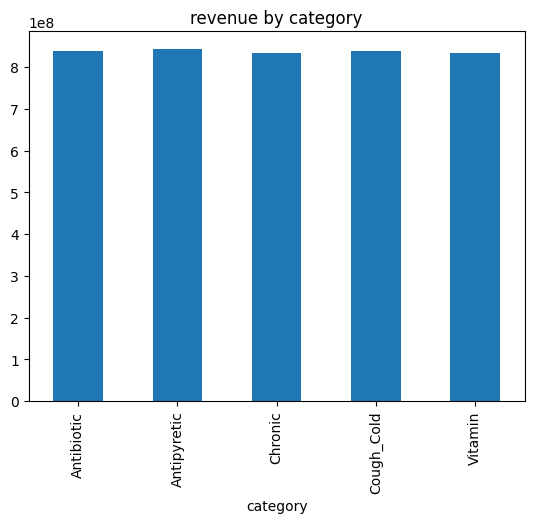

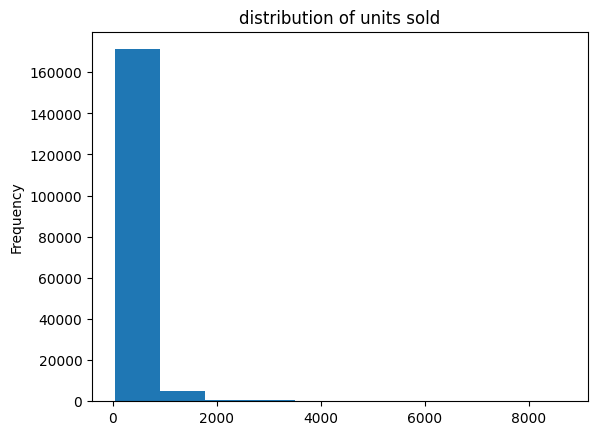

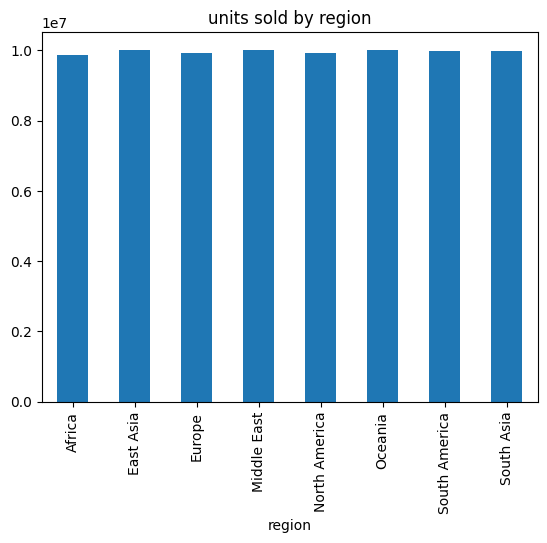

In [11]:
# plot simple distribution charts for revenue and inventory levels
df.groupby('category')['revenue'].sum().plot(kind='bar')
plt.title('revenue by category')
plt.show()

df['units_sold'].plot(kind='hist')
plt.title('distribution of units sold')
plt.show()

df.groupby('region')['units_sold'].sum().plot(kind='bar')
plt.title('units sold by region')
plt.show()